# Pesos para la uniformidad: de Gerchberg-Saxton a un arreglo uniforme

**Pregunta:** ¿Cómo convierten los pesos a Gerchberg-Saxton en un arreglo de trampas uniforme, con qué rapidez llega allí Gerchberg-Saxton ponderado y qué compra en el camino la variante aditiva adaptativa?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** notebook 01 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

El notebook anterior terminó con un lazo eficiente y no uniforme: con nueve trampas la dispersión de las potencias se estancó cerca de 7 por ciento. Los experimentos quieren trampas dentro de unos pocos por ciento entre sí, porque la profundidad de la trampa sigue a la potencia. Este notebook agrega el único cambio que lo arregla, un peso por trampa que recuerda cuán tenue ha sido, y mide lo que hace en las 100 trampas de C12. Leerás los pesos de la primera actualización, ejecutarás Gerchberg-Saxton simple, aditivo adaptativo y ponderado desde el mismo inicio, contarás las iteraciones que cada uno necesita para llegar a 5, 2 y 1 por ciento de dispersión, recorrerás la intensidad del término adaptativo y comprobarás cuánto depende la velocidad del inicio aleatorio.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m02_random_superposition, m04_gs, m05_gaa, m06_gsw

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def first_below(history, percent):
    """The first iteration whose relative spread is below ``percent``, or None."""
    return next((h["iteration"] for h in history if h["rel_std"] < percent), None)

numpy 2.4.6
matplotlib 3.11.2


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros, cubierto por la licencia del repositorio.
- Archivo leído: `data/examples/cases.json`, caso C12, 100 trampas sobre el SLM de 256 por 256 píxeles, la semilla del caso 20261028 y tres semillas contadas desde ella.

In [2]:
# case C12: the 10 x 10 array with a 30 iteration budget; every run starts from the same random-phase hologram
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C12_calibration"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
seed = rec["seed"]
phi0 = m02_random_superposition.run(setup, target, budget=Budget(1), rng=Rng(seed)).phi
print(f"{len(traps)} trampas, iteraciones del presupuesto: {rec['budget']['iterations']}, seed {seed}")

100 trampas, iteraciones del presupuesto: 30, seed 20261028


## Método

Sea $r_m = |V_m|/a_m$ la amplitud de la trampa $m$ relativa a su amplitud objetivo. Gerchberg-Saxton simple pide a las trampas $c_m = a_m V_m/|V_m|$, sea cual sea $r_m$. Gerchberg-Saxton ponderado (M06) guarda un peso por trampa, actualizado antes de cada iteración por $w_m \leftarrow w_m \langle r\rangle/r_m$, y pide $c_m = w_m V_m/|V_m|$: una trampa que salió tenue recibe un peso mayor y se le pide más la próxima vez, y a una brillante se le pide menos (Di Leonardo et al. 2007, ecuación 18, https://doi.org/10.1364/OE.15.001913). La variante aditiva adaptativa (M05) reescala en cambio cada pedido por $(1-\alpha) + \alpha/r_m$, sin memoria (el mismo artículo, ecuaciones 15 y 16; el corchete es una reconstrucción que el producto marca como no verificada, y depende de la escala absoluta de $|V_m|$, así que por defecto las amplitudes se expresan en unidades de su promedio). Con $\alpha = 0$ es Gerchberg-Saxton simple. Los pasos siguientes miden los primeros pesos, luego los tres métodos, luego la intensidad $\alpha$ y luego las semillas.

Los pesos de la primera actualización pueden calcularse sin ninguna iteración. Desde el inicio de fases aleatorias, lee las amplitudes $|V_m|$ de las 100 trampas con el modelo directo y forma $w = \langle r\rangle/r$. Si los pesos hacen lo que dice el texto, deben ser mayores donde la trampa es tenue, lo que es una correlación negativa con la potencia de la trampa. La celda imprime el rango de los pesos y esa correlación.

In [3]:
# the weight of the first update, w = mean(r) / r with r = |V|, from the traps' amplitudes at the start
v0 = forward.point_trap_fields(phi0, setup, traps)
r0 = np.abs(v0)
w1 = r0.mean() / r0
power0 = metrics.trap_intensities(v0)
print(f"pesos de la primera actualización, rango: {w1.min():.3f} to {w1.max():.3f}")
print(f"correlación del peso con la potencia de la trampa: {np.corrcoef(w1, power0)[0, 1]:.3f}")

pesos de la primera actualización, rango: 0.671 to 2.018
correlación del peso con la potencia de la trampa: -0.914


Ahora los tres métodos desde el mismo inicio durante 60 iteraciones, el doble del presupuesto del caso, para que los métodos lentos muestren su tendencia. La celda imprime la dispersión relativa en las iteraciones 1, 10, 30 y 60.

In [4]:
# plain GS, adaptive-additive GS (alpha 0.5) and weighted GS, 60 iterations from the same start
runs = {}
for name, method in (("M04", m04_gs), ("M05", m05_gaa), ("M06", m06_gsw)):
    runs[name] = method.run(setup, target, budget=Budget(60), rng=Rng(seed), init=phi0)
for name, res in runs.items():
    sigma = [h["rel_std"] for h in res.history]
    at = [sigma[k - 1] for k in (1, 10, 30, 60)]
    print(f"{name}: sigma en la iteración 1, 10, 30, 60 = " + ", ".join(f"{x:.2f}" for x in at) + " %")

M04: sigma en la iteración 1, 10, 30, 60 = 28.55, 21.55, 19.97, 16.89 %
M05: sigma en la iteración 1, 10, 30, 60 = 20.98, 15.02, 11.81, 11.34 %
M06: sigma en la iteración 1, 10, 30, 60 = 30.77, 3.81, 1.13, 0.59 %


La dispersión en iteraciones fijas oculta cuánto demora cada método en ser suficientemente bueno. La celda busca, para cada método, la primera iteración en que la dispersión queda bajo 5, 2 y 1 por ciento (None cuando nunca llega en 60 iteraciones), e imprime la eficiencia y la uniformidad de la iteración 30.

In [5]:
# how many iterations each method needs to bring the spread under 5, 2 and 1 percent
for name, res in runs.items():
    steps = [first_below(res.history, p) for p in (5, 2, 1)]
    h30 = res.history[29]
    print(f"{name}: iteraciones para llegar a 5, 2 y 1 por ciento {steps}")
    print(f"     tras 30 iteraciones e = {h30['efficiency']:.4f}, u = {h30['uniformity']:.4f}")

M04: iteraciones para llegar a 5, 2 y 1 por ciento [None, None, None]
     tras 30 iteraciones e = 0.8174, u = 0.5064
M05: iteraciones para llegar a 5, 2 y 1 por ciento [None, None, None]
     tras 30 iteraciones e = 0.8182, u = 0.7379
M06: iteraciones para llegar a 5, 2 y 1 por ciento [9, 18, 41]
     tras 30 iteraciones e = 0.8074, u = 0.9670


El método aditivo adaptativo tiene un parámetro. La celda lo ejecuta para $\alpha$ de 0 a 1 durante 30 iteraciones, y una vez más con el corchete tal como está impreso en la fuente, donde las amplitudes están en fracciones de la potencia de entrada, e imprime la eficiencia, la uniformidad y la dispersión de cada uno.

In [6]:
# the strength of the adaptive term: alpha from 0 (plain GS) to 1, and the bracket as printed ('absolute')
sweep = {}
for alpha in (0.0, 0.25, 0.75, 1.0):
    sweep[alpha] = m05_gaa.run(setup, target, budget=Budget(30), rng=Rng(seed), init=phi0, alpha=alpha).history[29]
sweep[0.5] = runs["M05"].history[29]
printed = m05_gaa.run(setup, target, budget=Budget(30), rng=Rng(seed), init=phi0, scale="absolute").history[29]
for alpha in sorted(sweep):
    h = sweep[alpha]
    print(f"alpha {alpha:4.2f}: e = {h['efficiency']:.4f}, u = {h['uniformity']:.4f}, sigma = {h['rel_std']:.2f} %")
print("corchete tal como se imprime:")
print(f"    e = {printed['efficiency']:.4f}, u = {printed['uniformity']:.4f}, sigma = {printed['rel_std']:.2f} %")

alpha 0.00: e = 0.8174, u = 0.5064, sigma = 19.97 %
alpha 0.25: e = 0.8195, u = 0.6786, sigma = 14.31 %
alpha 0.50: e = 0.8182, u = 0.7379, sigma = 11.81 %
alpha 0.75: e = 0.8178, u = 0.7691, sigma = 10.33 %
alpha 1.00: e = 0.8138, u = 0.0982, sigma = 62.53 %
corchete tal como se imprime:
    e = 0.8138, u = 0.5913, sigma = 14.94 %


Por último, cuánto de esto depende del inicio aleatorio. La celda ejecuta Gerchberg-Saxton ponderado desde otras tres semillas, cada una con su propio inicio de fases aleatorias, durante 60 iteraciones, e imprime las iteraciones para llegar a 5, 2 y 1 por ciento.

In [7]:
# does the speed of weighted GS depend on the random start? three other seeds, 60 iterations each
others = []
for s in (seed + 1, seed + 2, seed + 3):
    res = m06_gsw.run(setup, target, budget=Budget(60), rng=Rng(s))
    others.append([first_below(res.history, p) for p in (5, 2, 1)])
    print(f"semilla {s}: iteraciones para llegar a 5, 2 y 1 por ciento {others[-1]}")

semilla 20261029: iteraciones para llegar a 5, 2 y 1 por ciento [9, 17, 55]
semilla 20261030: iteraciones para llegar a 5, 2 y 1 por ciento [10, 25, 36]
semilla 20261031: iteraciones para llegar a 5, 2 y 1 por ciento [9, 20, 23]


Los pesos también son objetivos. Un objetivo puede pedir trampas de potencia distinta, con $w_m$ como intensidades objetivo, y entonces uniforme significa que $I_m/w_m$ es igual en todas partes. La celda le pide a C12 una rampa, un peso de 1 en la columna izquierda que sube 0,25 por columna hasta 3,25 en la columna derecha, e imprime para Gerchberg-Saxton simple y ponderado la dispersión y la uniformidad de la potencia dividida por el peso y la razón entre la potencia media de la columna derecha y la de la izquierda.

In [8]:
# weights are also targets: a ramp from weight 1 on the left column to 3.25 on the right column of the array
ramp = Target.from_traps(TrapSet(replace(t, weight=1.0 + 0.25 * (t.id % 10)) for t in traps))
column = np.arange(len(traps)) % 10
for name, method in (("M04", m04_gs), ("M06", m06_gsw)):
    res = method.run(setup, ramp, budget=Budget(30), rng=Rng(seed), init=phi0)
    scaled = metrics.trap_intensities(res.fields, ramp.traps.weight)
    power = metrics.trap_intensities(res.fields)
    print(f"{name}: dispersión de la potencia sobre el peso {metrics.rel_std(scaled):.2f} %")
    print(f"     u = {metrics.uniformity(scaled):.4f}")
    ratio = power[column == 9].mean() / power[column == 0].mean()
    print(f"     potencia de la columna derecha sobre la izquierda (objetivo 3,25): {ratio:.2f}")

M04: dispersión de la potencia sobre el peso 22.57 %
     u = 0.4358
     potencia de la columna derecha sobre la izquierda (objetivo 3,25): 2.57
M06: dispersión de la potencia sobre el peso 1.17 %
     u = 0.9644
     potencia de la columna derecha sobre la izquierda (objetivo 3,25): 3.25


Gerchberg-Saxton ponderado respeta la rampa: la dispersión de la potencia sobre el peso es 1,17 por ciento con una uniformidad de 0,9644, y la columna derecha es 3,25 veces más brillante que la izquierda, exactamente la razón pedida. Gerchberg-Saxton simple la ignora en buena parte: una dispersión de 22,57 por ciento, una uniformidad de 0,4358 y una razón de 2,57, porque pide las amplitudes correctas pero no tiene manera de corregir lo que sale mal. Esa es la razón por la que los pesos del algoritmo llevan el nombre de los objetivos: un objetivo con trampas desiguales no es un problema distinto para el método ponderado. La prueba es una rampa en un arreglo, y no muestra qué razón puede entregar el SLM antes de que la eficiencia se desplome.

La primera figura grafica la dispersión relativa contra la iteración para los tres métodos desde el inicio común, en un eje logarítmico, con una línea punteada en 1 por ciento.

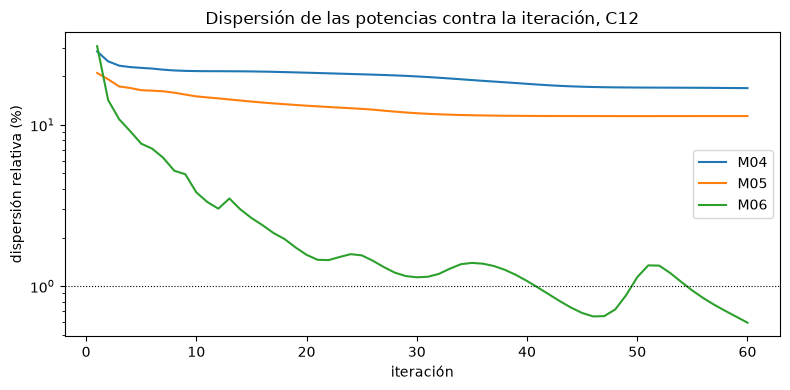

In [9]:
# the relative spread against the iteration for the three methods, on a log axis
fig, ax = plt.subplots(figsize=(8, 4))
for name, res in runs.items():
    ax.semilogy([h["iteration"] for h in res.history], [h["rel_std"] for h in res.history], label=name)
ax.axhline(1.0, color="k", lw=0.8, ls=":")
ax.set_xlabel("iteración")
ax.set_ylabel("dispersión relativa (%)")
ax.set_title("Dispersión de las potencias contra la iteración, C12")
ax.legend()
fig.tight_layout()
plt.show()

Gerchberg-Saxton simple baja de 28,55 a 21,55 por ciento en diez iteraciones y luego casi no se mueve, 19,97 en la iteración 30 y 16,89 en la 60. La curva aditiva adaptativa queda bajo ella todo el tiempo, en 11,81 por ciento en la iteración 30 y 11,34 en la 60, y también se aplana. Gerchberg-Saxton ponderado parte peor, en 30,77 por ciento tras una iteración, lo que leo como los primeros pesos que sobrepasan, y luego cae con fuerza: 3,81 por ciento en la iteración 10, 1,13 en la 30 y 0,59 en la 60, y es la única curva que cruza la línea punteada. La curva no es monótona: rebota hacia las iteraciones 13, 34 y 51, y en la iteración 50 vuelve a estar sobre 1 por ciento, de modo que llegar una vez a 1 por ciento no es lo mismo que quedarse bajo él. La figura no muestra cómo evolucionan los pesos mismos ni dice lo que cuestan, lo que sí hacen las eficiencias de la celda anterior y la figura siguiente.

La segunda figura tiene dos paneles. A la izquierda, el peso de la primera actualización contra la potencia de la trampa al inicio. A la derecha, la uniformidad y la eficiencia tras 30 iteraciones contra $\alpha$.

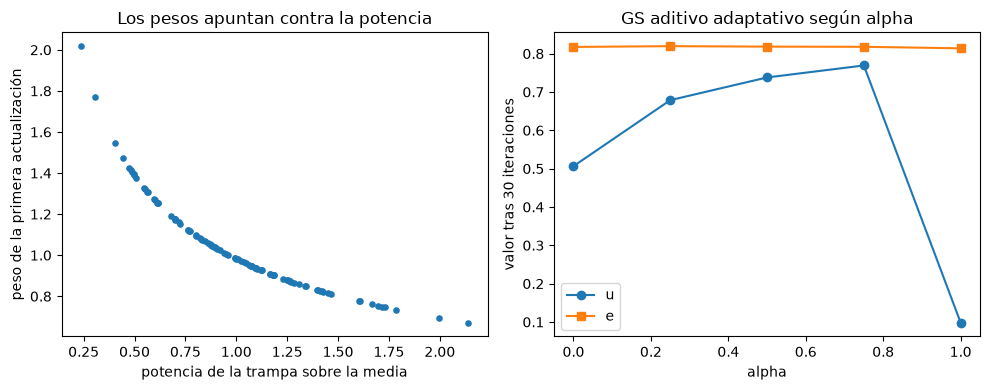

In [10]:
# left: the weight of the first update against the trap power at the start; right: the alpha sweep
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(power0 / power0.mean(), w1, s=14)
ax1.set_xlabel("potencia de la trampa sobre la media")
ax1.set_ylabel("peso de la primera actualización")
ax1.set_title("Los pesos apuntan contra la potencia")
alphas = sorted(sweep)
ax2.plot(alphas, [sweep[a]["uniformity"] for a in alphas], "o-", label="u")
ax2.plot(alphas, [sweep[a]["efficiency"] for a in alphas], "s-", label="e")
ax2.set_xlabel("alpha")
ax2.set_ylabel("valor tras 30 iteraciones")
ax2.set_title("GS aditivo adaptativo según alpha")
ax2.legend()
fig.tight_layout()
plt.show()

A la izquierda los pesos bajan cuando la potencia sube, de 2,018 para las trampas más tenues a 0,671 para las más brillantes, y los puntos caen sobre una curva suave decreciente, la inversa de la raíz cuadrada de la potencia, que la correlación lineal de menos 0,914 de la primera celda describe solo de forma aproximada. Ese es todo el mecanismo: pedir más donde salió poco. A la derecha la uniformidad sube de 0,5064 con $\alpha = 0$ a 0,7691 con $\alpha = 0,75$ mientras la eficiencia queda entre 0,8174 y 0,8195, de modo que un término adaptativo moderado sale gratis, pero con $\alpha = 1$ la uniformidad se desploma a 0,0982 con una dispersión de 62,53 por ciento: sin término de amplitud, el pedido de una trampa es el inverso de su propia amplitud, lo que leo como un sobrepaso, aunque este notebook no prueba esa lectura. El corchete tal como se imprime, con las amplitudes en unidades absolutas, llega a una uniformidad de 0,5913, mejor que Gerchberg-Saxton simple y peor que la versión escalada con 0,7379, y por eso el producto normaliza.

## Resultados

**Respuesta:** Los pesos convierten a Gerchberg-Saxton en un arreglo uniforme pidiendo a cada trampa más cuando salió tenue y menos cuando salió brillante. En C12 los pesos de la primera actualización van de 0,671 a 2,018 y tienen una correlación de menos 0,914 con la potencia de la trampa. Con ellos la dispersión relativa baja a 3,81 por ciento en la iteración 10 y a 1,13 por ciento en la 30, frente a 21,55 y 19,97 por ciento de Gerchberg-Saxton simple y 15,02 y 11,81 por ciento de la variante aditiva adaptativa. Con la semilla del caso Gerchberg-Saxton ponderado necesita 9 iteraciones para bajar de 5 por ciento, 18 para bajar de 2 y 41 para bajar de 1, y con otras tres semillas 9 a 10, 17 a 25 y 23 a 55, de modo que la velocidad depende del inicio aleatorio pero el orden de magnitud no. La uniformidad es 0,9670 frente a 0,5064 y 0,7379, con un costo de 0,0100 en eficiencia (0,8074 frente a 0,8174). El término adaptativo es gratuito hasta $\alpha = 0,75$ y se rompe con $\alpha = 1$, donde la uniformidad es 0,0982.

## Resumen

Un peso por trampa con memoria es lo que hace uniforme a Gerchberg-Saxton. Cuesta cerca de una centésima de la eficiencia en este arreglo, demora desde 9 iteraciones (hasta 5 por ciento) hasta 55 (hasta 1 por ciento) en llegar a la dispersión que pide un experimento, según el inicio, y no necesita nada más que los campos de las trampas que la iteración ya calcula. La variante aditiva adaptativa es el camino intermedio barato: mejora la uniformidad sin costo en eficiencia y nunca alcanza el resultado ponderado. El notebook siguiente pregunta si la variante de fase fija de los pesos del producto está a la altura del estado del arte en un arreglo de mil trampas.

## Referencias

- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.